<a href="https://colab.research.google.com/github/MaheliN1218/TelcoChurn/blob/Taksk1/sample.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Telco Customer Churn: Exploratory Data Analysis


### 1. Initialisation and dataset insight

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("Telco.csv")
print("Shape:", df.shape)
df.head(3)

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


In [ ]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
df.nunique().sort_values()

,0
gender,2
SeniorCitizen,2
Partner,2
Dependents,2
PhoneService,2
PaperlessBilling,2
Churn,2
MultipleLines,3
TechSupport,3
StreamingTV,3


### 2.Data quality checks

 Checking whether any columns have missing values.

In [ ]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
missing = df.isna().sum()
print("Missing values per column:")
print(missing)

Missing values per column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


Converted invalid whitespace strings in TotalCharges to NaN to expose the 11 missing values for downstream preprocessing.

In [ ]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
missing = df.isna().sum()
print("Missing values per column:")
print(missing)

Missing values per column:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


Total charges have 11 missing values.

To handle missing values imputation is done.

In [ ]:
# Convert blank strings to true NaN first
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

print(df[df['TotalCharges'].isna()][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']])

      customerID  tenure  MonthlyCharges  TotalCharges
488   4472-LVYGI       0           52.55           NaN
753   3115-CZMZD       0           20.25           NaN
936   5709-LVOEQ       0           80.85           NaN
1082  4367-NUYAO       0           25.75           NaN
1340  1371-DWPAZ       0           56.05           NaN
3331  7644-OMVMY       0           19.85           NaN
3826  3213-VVOLG       0           25.35           NaN
4380  2520-SGTTA       0           20.00           NaN
5218  2923-ARZLG       0           19.70           NaN
6670  4075-WKNIU       0           73.35           NaN
6754  2775-SEFEE       0           61.90           NaN


TotalCharges are NaN because tenure is 0. Therefore it's reasonable to impute total charges as 0.

In [ ]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)

In [ ]:
print("Customer IDs duplicates:", df["customerID"].duplicated().sum())
print("Duplicate rows (ignoring ID):", df.drop(columns="customerID").duplicated().sum())



Customer IDs duplicates: 0
Duplicate rows (ignoring ID): 22


`customerID` is only an identifier and has no predictive value, so it is excluded from the analysis from this point on. The target is encoded as 1 = churned, 0 = stayed.

In [ ]:
df = df.drop(columns="customerID")
df["Churn"] = (df["Churn"] == "Yes").astype(int)

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in df.columns if c not in num_cols + ["Churn"]]
print("Numeric:", num_cols)
print("Categorical:", cat_cols)

Numeric: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


### 2.Handling Class imbalance

Heavy class imbalance affect the evaluation causeing inaccuracies.

In [ ]:
counts = df["Churn"].value_counts()
pct = df["Churn"].value_counts(normalize=True) * 100
print(pd.DataFrame({"count": counts, "percent": pct.round(2)}))


       count  percent
Churn                
0       5174    73.46
1       1869    26.54


<Axes: xlabel='Churn', ylabel='count'>

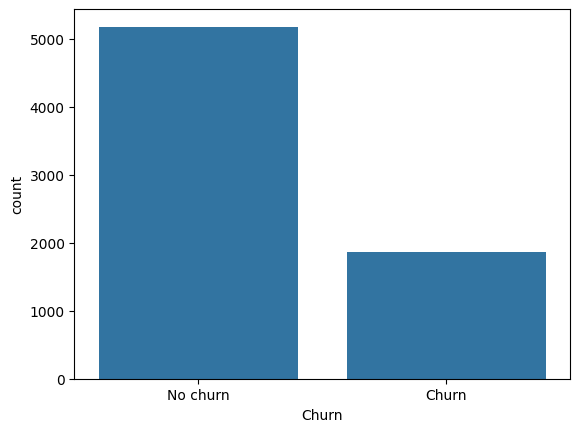

In [ ]:
sns.countplot(x=df["Churn"].map({0: "No churn", 1: "Churn"}))



**Insight**: From the bar chart it's evident that the customers around 1 in 4 customers churn, creating an imbalanced target variable. A model could score 73% accuracy by never predicting churn at all. Therefore, precision, recall, F1, and ROC-AUC are used alongside a stratified split to properly detect churners.

###6. Numeric features
6.1 Distributions by churn status

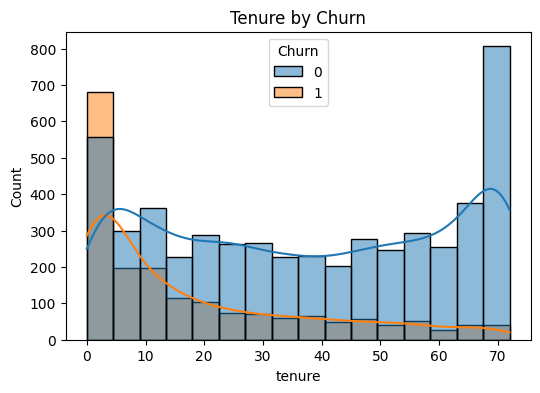

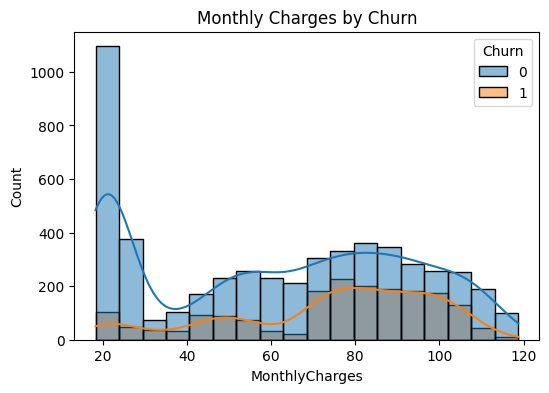

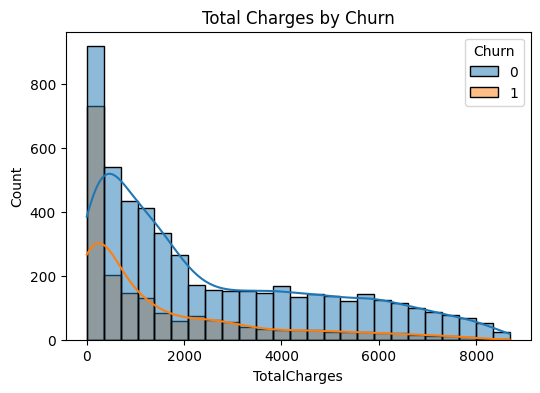

In [ ]:
# 1. Tenure vs Churn
plt.figure(figsize=(6, 4))
sns.histplot(data=df, x="tenure", hue="Churn", kde=True)
plt.title("Tenure by Churn")
plt.show()

# 2. Monthly Charges vs Churn
plt.figure(figsize=(6, 4))
sns.histplot(data=df, x="MonthlyCharges", hue="Churn", kde=True)
plt.title("Monthly Charges by Churn")
plt.show()

# 3. Total Charges vs Churn
plt.figure(figsize=(6, 4))
sns.histplot(data=df, x="TotalCharges", hue="Churn", kde=True)
plt.title("Total Charges by Churn")
plt.show()

6.2 Box plots and summary by churn status

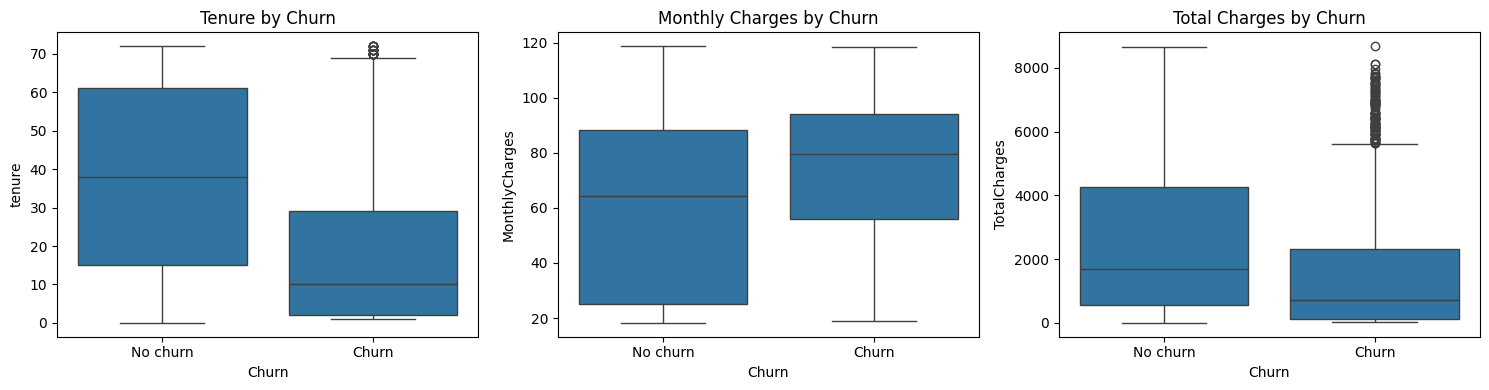

      tenure               MonthlyCharges               TotalCharges           \
        mean median    std           mean median    std         mean   median   
Churn                                                                           
0      37.57   38.0  24.11          61.27  64.43  31.09      2549.91  1679.52   
1      17.98   10.0  19.53          74.44  79.65  24.67      1531.80   703.55   

                
           std  
Churn           
0      2329.95  
1      1890.82  


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create canvas for 3 side-by-side plots
plt.figure(figsize=(15, 4))

# 1. Tenure Boxplot
plt.subplot(1, 3, 1)
sns.boxplot(data=df, x="Churn", y="tenure")
plt.xticks([0, 1], ["No churn", "Churn"])
plt.title("Tenure by Churn")

# 2. Monthly Charges Boxplot
plt.subplot(1, 3, 2)
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.xticks([0, 1], ["No churn", "Churn"])
plt.title("Monthly Charges by Churn")

# 3. Total Charges Boxplot
plt.subplot(1, 3, 3)
sns.boxplot(data=df, x="Churn", y="TotalCharges")
plt.xticks([0, 1], ["No churn", "Churn"])
plt.title("Total Charges by Churn")

plt.tight_layout()
plt.show()

# Summary table of numeric statistics split by Churn
stats_table = df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].agg(["mean", "median", "std"]).round(2)
print(stats_table)

**Insights (verify against your output):**
- `tenure`: churners have much shorter tenure; most churn happens in the first months. Non-churners show a second peak at long tenures (loyal customers).
- `MonthlyCharges`: churners tend to pay more per month.
- `TotalCharges`: right-skewed and lower for churners, mostly because they stay a shorter time.
- No extreme outliers need removal, but the skew in `TotalCharges` is another reason to scale features for KNN and Logistic Regression.

### 6.3 Churn rate across tenure bands
Binning tenure makes the relationship easier to read.

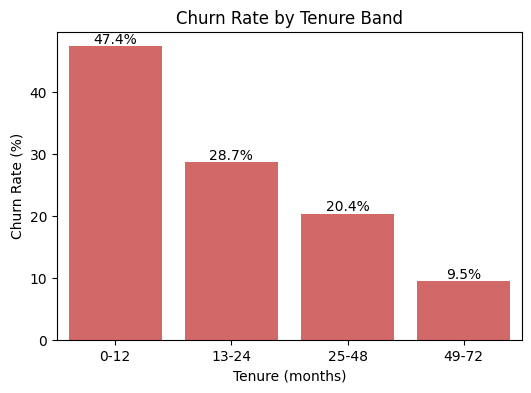

In [ ]:
# 1. Create tenure groups (bands)
df["tenure_band"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12", "13-24", "25-48", "49-72"]
)

# 2. Calculate churn percentage for each group
band_churn = df.groupby("tenure_band", observed=True)["Churn"].mean() * 100
band_df = band_churn.reset_index()

# 3. Plot the bar chart
plt.figure(figsize=(6, 4))
ax = sns.barplot(data=band_df, x="tenure_band", y="Churn", color="#e45756")

# Add percentage labels on top of the bars in one line
ax.bar_label(ax.containers[0], fmt="%.1f%%")

# Add labels and title
plt.title("Churn Rate by Tenure Band")
plt.xlabel("Tenure (months)")
plt.ylabel("Churn Rate (%)")

plt.show()

# 4. Remove the temporary column so it doesn't affect later steps
df = df.drop(columns="tenure_band")

## 7. Categorical features
### 7.1 Churn rate for every categorical feature
The plot below shows the percentage of customers who churned within each category. The dashed line is the overall churn rate, so bars above the line mark higher-risk groups.

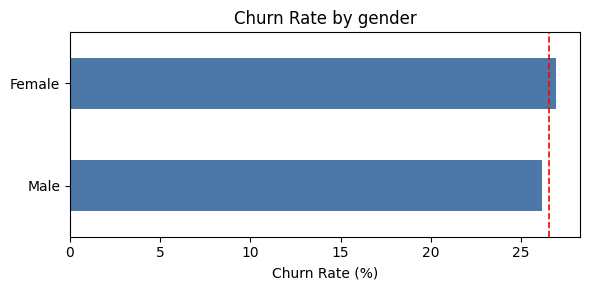

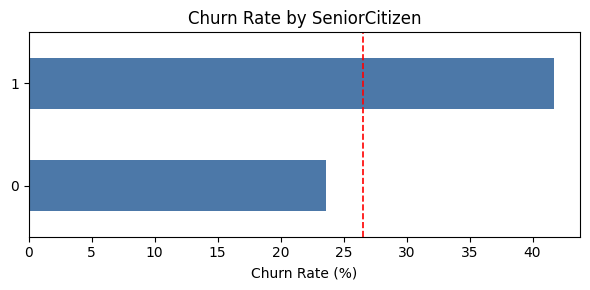

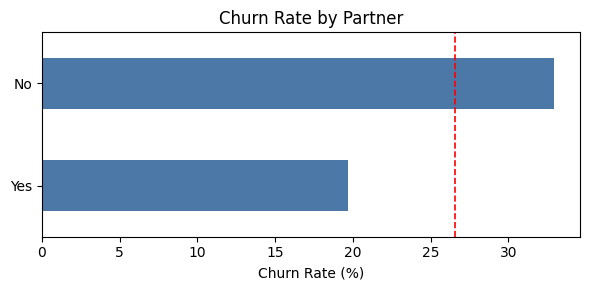

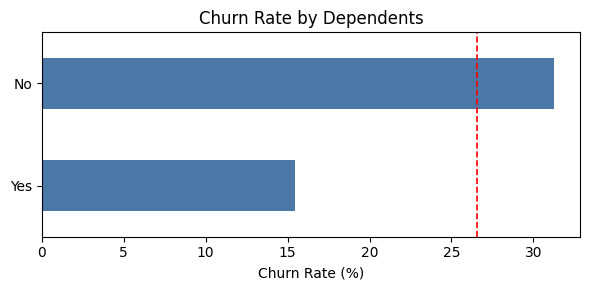

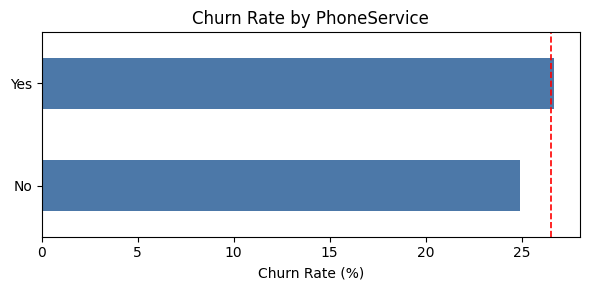

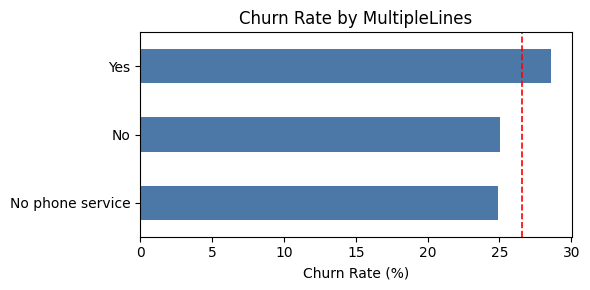

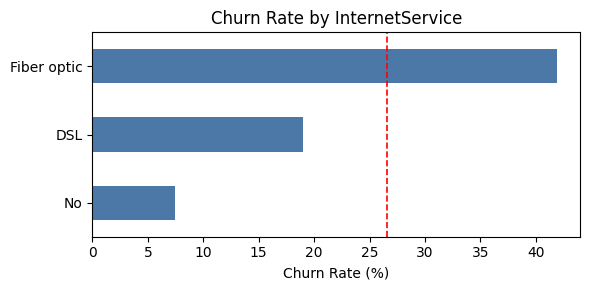

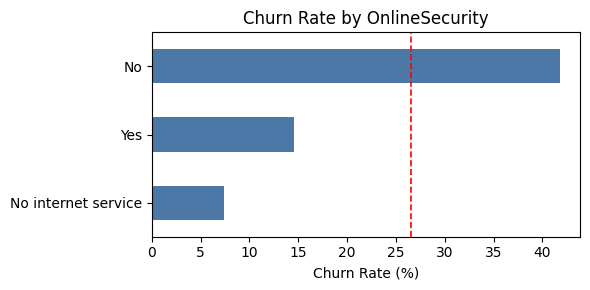

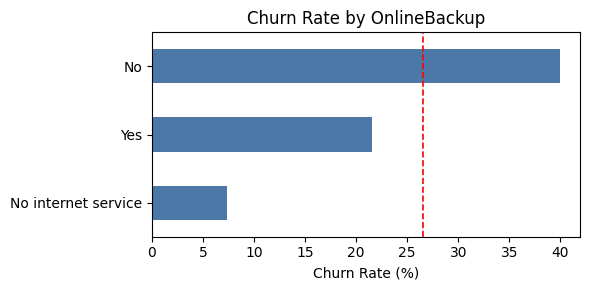

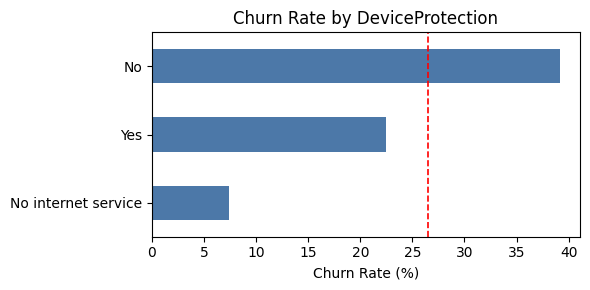

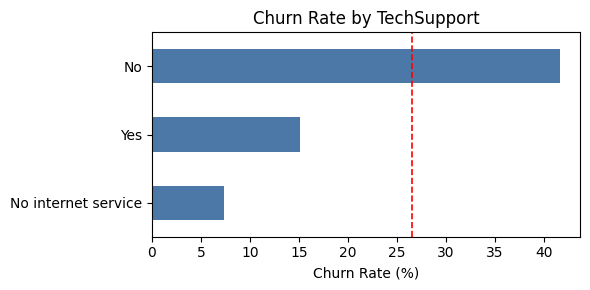

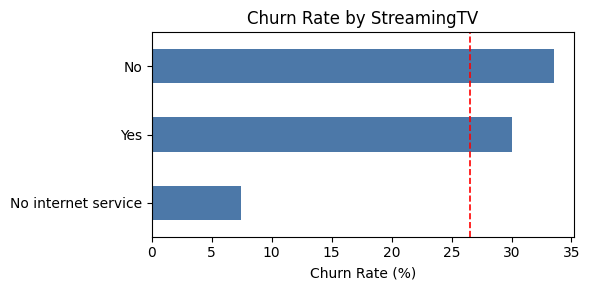

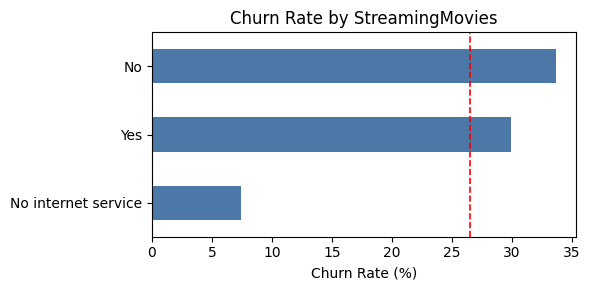

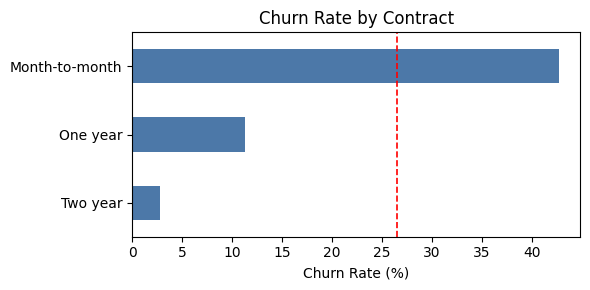

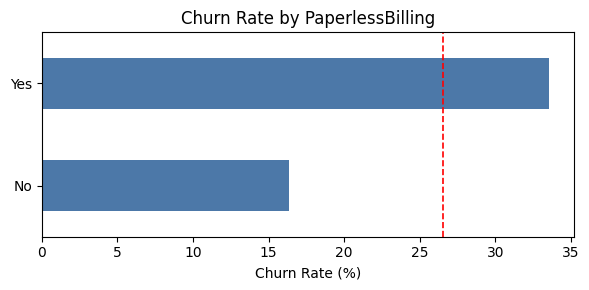

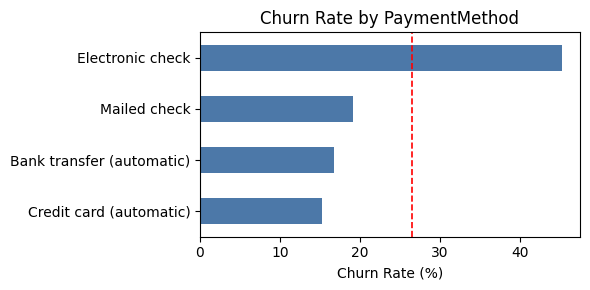

In [ ]:
# Baseline churn rate across the company (~26.5%)
overall_rate = df["Churn"].mean() * 100

# Loop through and plot each categorical column simply
for col in cat_cols:
    plt.figure(figsize=(6, 3))

    # Calculate churn % per group and sort
    churn_rates = (df.groupby(col)["Churn"].mean() * 100).sort_values()

    # Simple horizontal bar plot
    churn_rates.plot(kind="barh", color="#4c78a8")

    # Red dashed benchmark line
    plt.axvline(overall_rate, color="red", linestyle="--", linewidth=1.2)

    plt.title(f"Churn Rate by {col}")
    plt.xlabel("Churn Rate (%)")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

### 7.2 Ranking features by strength of association
A quick, model-free ranking: the spread (max - min) of churn rate across the categories of each feature.

Contract            39.9
InternetService     34.5
OnlineSecurity      34.4
TechSupport         34.2
OnlineBackup        32.5
DeviceProtection    31.7
PaymentMethod       30.0
StreamingMovies     26.3
StreamingTV         26.1
SeniorCitizen       18.1
PaperlessBilling    17.2
Dependents          15.8
Partner             13.3
MultipleLines        3.7
PhoneService         1.8
gender               0.8
dtype: float64


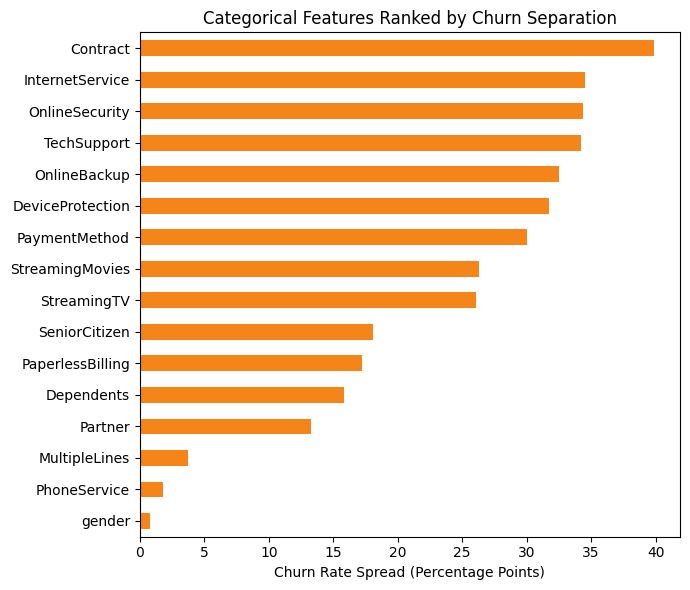

In [ ]:
# 1. Calculate churn rate difference (spread) for each categorical column
spread_dict = {}

for col in cat_cols:
    rates = df.groupby(col)["Churn"].mean() * 100
    spread_dict[col] = rates.max() - rates.min()

# Convert to a Series and sort from highest to lowest impact
spread_series = pd.Series(spread_dict).sort_values(ascending=False).round(1)
print(spread_series)

# 2. Plot the ranking as a horizontal bar chart
plt.figure(figsize=(7, 6))
spread_series.sort_values(ascending=True).plot(kind="barh", color="#f58518")

plt.xlabel("Churn Rate Spread (Percentage Points)")
plt.title("Categorical Features Ranked by Churn Separation")
plt.tight_layout()
plt.show()

Insight: Ranking categorical attributes by churn-rate separation confirms that account and service structure are the primary drivers of attrition. Contract, InternetService, OnlineSecurity, and TechSupport provide the highest discriminative power, exhibiting wide spreads between retained and churned customer groups. Conversely, demographic variables like gender and service basic PhoneService display virtually zero separation, indicating they contribute minimal individual predictive value for the classification models.

### 7.3 Interaction: contract type and charges

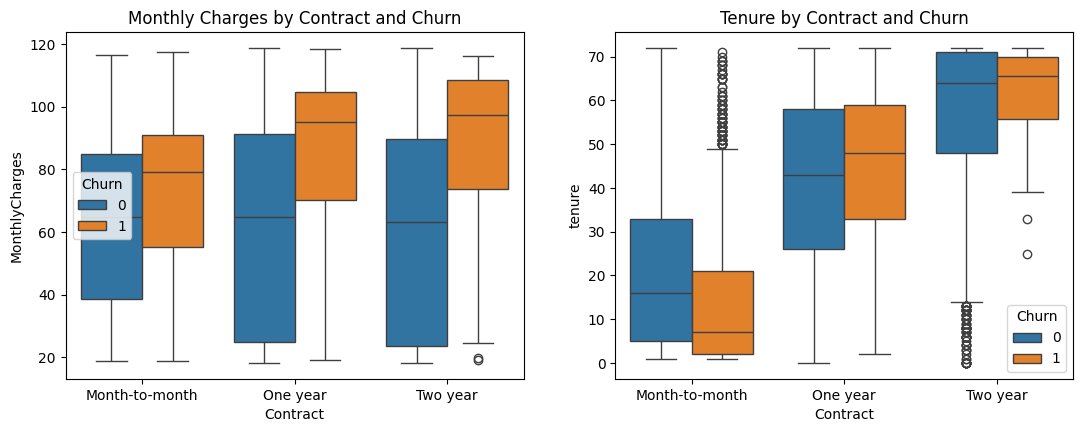

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(13, 4.5))

# Plot 1: Monthly Charges across Contracts, split by Churn
plt.subplot(1, 2, 1)
sns.boxplot(data=df, x="Contract", y="MonthlyCharges", hue="Churn")
plt.title("Monthly Charges by Contract and Churn")

# Plot 2: Tenure across Contracts, split by Churn
plt.subplot(1, 2, 2)
sns.boxplot(data=df, x="Contract", y="tenure", hue="Churn")
plt.title("Tenure by Contract and Churn")


plt.show()

## 8. Correlation analysis
Correlation among numeric features (including the binary target) shows redundancy and linear relationships.

Text(0.5, 1.0, 'Correlation matrix')

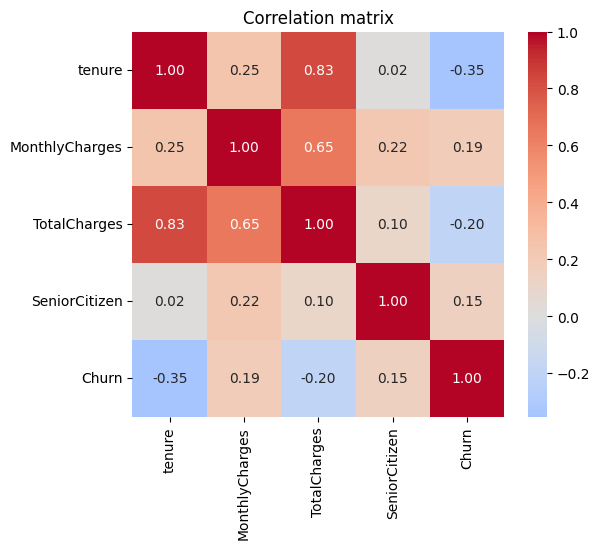

In [ ]:
corr = df[num_cols + ["SeniorCitizen", "Churn"]].corr()
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")


**Insight:** `tenure` and `TotalCharges` are strongly correlated (TotalCharges is roughly tenure x MonthlyCharges). This is acceptable for Random Forest, but can inflate coefficient variance in Logistic Regression, so regularisation is useful. `tenure` has the strongest negative correlation with churn.

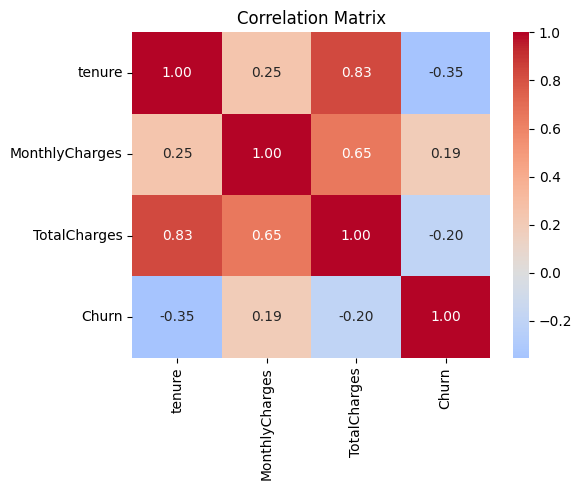

In [ ]:
corr = df[num_cols + ["Churn"]].corr()
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

## 9. Engineered feature check (optional)
The number of add-on services a customer subscribes to may relate to churn.

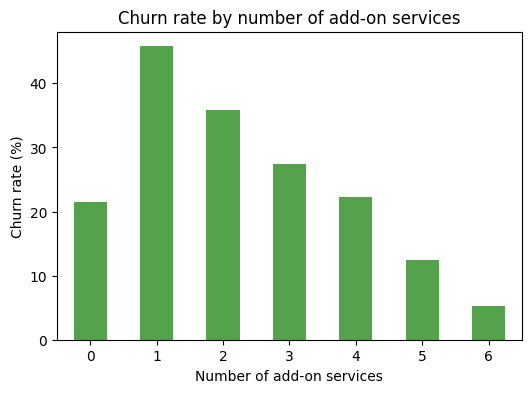

In [ ]:
service_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                "TechSupport", "StreamingTV", "StreamingMovies"]
df["n_services"] = (df[service_cols] == "Yes").sum(axis=1)
(df.groupby("n_services")["Churn"].mean() * 100).plot(kind="bar", figsize=(6, 4), color="#54a24b")
plt.ylabel("Churn rate (%)"); plt.xlabel("Number of add-on services"); plt.xticks(rotation=0)
plt.title("Churn rate by number of add-on services")
df = df.drop(columns="n_services")

In [ ]:
# Replace redundant subcategories
replace_cols = [
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies'
]
for col in replace_cols:
    df[col] = df[col].replace({'No internet service': 'No'})

df['MultipleLines'] = df['MultipleLines'].replace({'No phone service': 'No'})

## 10. Summary of findings and implications for modelling

| Finding | Implication |
|---|---|
| ~27% churn, ~73% retained | Use stratified splitting; evaluate with F1, recall, precision, ROC-AUC; use `class_weight="balanced"` where supported |
| 11 blank `TotalCharges` (tenure = 0) | Convert to numeric and impute inside the pipeline |
| `customerID` has no predictive value | Drop it |
| Numeric features on different scales and skewed | Standardise for KNN and Logistic Regression |
| Many categorical features | One-hot encode |
| `tenure` and `TotalCharges` highly correlated | Regularise Logistic Regression; Random Forest is robust |
| Contract, tenure, internet service, payment method and add-ons are the strongest signals | Expect these to dominate feature importances |
| gender, phone service weakly related | Consider excluding; gender is sensitive (ethics) |

**Next step:** build the preprocessing pipeline and train KNN, Logistic Regression and Random Forest with hyperparameter tuning (see `churn_pipeline.py`).